# Company-name harmonisation

**Goal.** Patent applicants appear under many spellings (`NOKIA CORPORATION`, `NOKIA (DEUTSCHLAND)`, `NOKIA MOBILE PHONES LIMITED`, ...). This notebook groups the spellings that refer to the same organisation and gives each group one representative name, so that patent counts and concentration measures can be computed per organisation and not per spelling.

**Method in one paragraph.** We follow the three-stage structure of Terrorizer (Ascione & Sterzi, 2024): *parsing* (name cleaning), *matching* (a similarity weight for every pair of names) and *filtering* (a graph in which names are nodes and similar pairs are weighted edges, cut into communities with the Louvain algorithm). No step is learned from labels: the gold standard is used to evaluate the result, never to choose the threshold.

| Stage | Cell(s) | What it does |
|---|---|---|
| Parsing | `clean()` | Normalises and standardises every name |
| Matching | embeddings + `pair_features()` | Gives **every** pair of cleaned names a weight in [0, 1] |
| Filtering | Otsu threshold + Louvain | Keeps the strong edges, finds communities, names each community |
| Evaluation | pairwise precision / recall / F1 | Compares the communities with the gold standard |

*This first version is written for firms. The cleaning step is generic (it also works for universities); adapting the later stages to universities and individuals is future work.*

References are listed at the end of the notebook.

In [1]:
# uninstalled dependencies
%pip install sentence-transformers networkx matplotlib
import re                                           # regular expressions (name cleaning)
import unicodedata                                  # Unicode normalisation (name cleaning)
from difflib import SequenceMatcher                 # letter-by-letter similarity ratio between two strings
from itertools import combinations                  # all pairs of names
from math import comb                               # number of pairs inside a group (evaluation)
import numpy as np
import pandas as pd
import networkx as nx                               # graph of names
import networkx.algorithms.community as nx_comm     # Louvain community detection
import matplotlib.pyplot as plt                     # charts
from sentence_transformers import SentenceTransformer   # embedding model


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Config

GOLD_FILE = 'PATSTAT_500_label_datav4.csv'   # gold standard: raw names + true group
NAME_COL = 'comp'                            # column with the raw applicant name
GROUP_COL = 'Group'                          # column with the true group (gold standard only)
WEIGHT_COL = None                            # e.g. 'n_families' on the quantum sample; None -> every row counts 1

EMBEDDING_MODEL = "Vsevolod/company-names-similarity-sentence-transformer"  # embedding model purpose-built for company names

# Edge weight = weighted average of three similarities. The coefficients are >= 0 and sum to 1,
# so the edge weight can never exceed 1 (see the "Edge weight" section).
SCORE_WEIGHTS = {"cosine": 0.55, "jaccard": 0.30, "edit": 0.15}
SCORE_FLOOR = 0.35        # pairs below this weight are not edges (also the lower end of Otsu's pool and of the sweep)

# Graph cut
LOUVAIN_RESOLUTION = 1.0  # library default (also the starting value used by Terrorizer)
LOUVAIN_SEED = 42         # Louvain is randomised: a fixed seed makes every run identical
SWEEP_GRID = np.arange(0.40, 0.851, 0.025)   # thresholds tried in the stability check 

## Step 1 - Parsing: name cleaning

Two spellings can only be compared fairly once trivial differences (case, accents, punctuation, legal forms) are removed. `clean()` does this in a fixed, deterministic order and **every line of the function is commented**. It is deliberately **conservative**: it never deletes words from the middle of a name. It only (i) removes noise characters, (ii) removes legal forms at the very start or end of the name, (iii) drops a short list of filler words, and (iv) standardises a few frequent words (`UNIVERSITY -> UNIV`, `TECHNOLOGIES -> TECH`, ...).

Main operations, in order:
1. **Unicode normalisation** (NFKC/NFKD, [UAX #15](https://unicode.org/reports/tr15/)): folds full-width characters (`ＮＴＴ -> NTT`) and removes Latin accents (`MÜLLER -> MULLER`), while CJK characters are left intact.
2. **Mixed names**: when a CJK name is followed by its Latin version, only the Latin part is kept.
3. **Noise**: care-of addresses (`C/O ...`), dots and symbols (`S.P.A. -> SPA`), and Latin and CJK legal forms (`INC`, `GMBH`, `株式会社`, ...) at the start or end of the name.
4. **Standardisation** of frequent words and removal of filler words (`OF`, `THE`, `DE`, ...).

*Country names are intentionally not removed.* A trailing country is often part of the institution's name; stripping it made different institutions identical (`University of Hong Kong` and `University of Iceland` both became `UNIV`), so that step was tested and dropped perchè nel goal standard andava molto bene ma in un settore contante uivesità no.

*Literature.* Cleaning and standardising names before matching is the usual structure of patent-name harmonisation (Magerman, Van Looy & Song, 2006; Callaert et al., 2011) and the "parsing" stage of Terrorizer (Ascione & Sterzi, 2024). The lists below (legal forms, standard words, filler words) are hand-written from common conventions; nothing is learned from data.

In [3]:
# Legal forms, removed ONLY at the start or end of a name (e.g. "ACME INC" -> "ACME"); words inside a name are never touched
FORMS = ["INC", "INCORPORATED", "LLC", "LLP", "LP", "LTD", "LIMITED", "CORP", "CORPORATION", "CO", "COMPANY", "PLC", "GMBH", "MBH",
         "AG", "KG", "SE", "SA", "SAS", "SARL", "SRL", "SPA", "SL", "BV", "NV", "OY", "OYJ", "AB", "AS", "ASA", "APS", "PTY", "PTE",
         "KK", "KABUSHIKI KAISHA", "SP Z OO", "OOO", "BHD", "SDN", "PVT", "LTDA"]
# Regex alternation of the forms, longest first, so that "CORPORATION" is tried before "CO" and "INCORPORATED" before "INC"
FORMS_RE = "|".join(sorted(FORMS, key=len, reverse=True))
# Chinese / Japanese / Korean equivalents of "Co., Ltd.", also removed only at the start or end of a name
FORMS_CJK = "股份有限公司|有限责任公司|有限責任公司|有限公司|株式会社|有限会社|合同会社|주식회사|公司"
# Frequent institutional words (and their spellings in other languages) mapped to one short standard form
WORDS = {"UNIVERSITY": "UNIV", "UNIVERSITAET": "UNIV", "UNIVERSITAT": "UNIV", "UNIVERSITE": "UNIV", "UNIVERSIDAD": "UNIV",
         "UNIVERSITA": "UNIV", "INSTITUTE": "INST", "INSTITUT": "INST", "INSTITUTO": "INST", "TECHNOLOGY": "TECH",
         "TECHNOLOGIES": "TECH", "TECHNOLOGICAL": "TECH", "LABORATORY": "LAB", "LABORATORIES": "LAB", "LABS": "LAB",
         "CENTRE": "CENTER", "SCIENCES": "SCIENCE", "大學": "大学"}
# Filler words with no identifying power (articles, conjunctions, prepositions in English, French, Italian, German), dropped everywhere
FILLER = {"OF", "THE", "FOR", "AND", "DE", "DI", "DU", "DES", "ET", "UND"}


def clean(name):
    # 1a. NFKC folds compatibility characters (full-width letters, ligatures) into standard ones, then .upper() makes
    #     the comparison case-insensitive, then NFKD splits every accented letter into base letter + combining accent
    s = unicodedata.normalize("NFKD", unicodedata.normalize("NFKC", str(name)).upper())
    # 1b. Drop the combining accents that follow a Latin character (code point < U+0250), so "MÜLLER" -> "MULLER";
    #     accents/marks attached to non-Latin characters (Japanese, Korean) are kept; NFC then re-composes what is left
    s = unicodedata.normalize("NFC", "".join(c for i, c in enumerate(s) if not (unicodedata.combining(c) and s[i - 1] < "ɐ")))
    # 2. Remove noise characters: patent-office markers (▲ ▼), question marks, dots ("S.P.A." -> "SPA", "U.K." -> "UK") and apostrophes
    s = re.sub(r"[▲▼?.'’]", "", s)
    # 3a. Look for a Latin-alphabet tail that follows a non-ASCII (e.g. CJK) character: "株式会社ＮＴＴ NTT CORPORATION" -> "NTT CORPORATION"
    latin = re.search(r"[^\x00-\x7f]([A-Z0-9][A-Z0-9 ,&\-/]+)$", s)
    # 3b. Use that Latin tail only if it contains at least 3 letters (avoids keeping accidental one-letter or numeric fragments)
    if latin and len(re.sub(r"[^A-Z]", "", latin.group(1))) >= 3:
        # 3c. Replace the whole name with its Latin version
        s = latin.group(1)
    # 4. Cut "C/O ..." (care-of address) and everything after it; write Danish/Norwegian "A/S" as "AS" so that the slash
    #    does not break it; write "&" as " AND " so that "A&B" and "A AND B" become the same string
    s = re.sub(r"\bC/O\b.*$", "", s).replace("A/S", "AS").replace("&", " AND ")
    # 5. Turn every remaining punctuation mark or underscore into a space (letters, digits and CJK characters are kept),
    #    trim, then remove a CJK legal form if it sits at the very start or at the very end of the name
    s = re.sub(rf"^({FORMS_CJK})|({FORMS_CJK})$", "", re.sub(r"[^\w ]|_", " ", s).strip())
    # 6. Standardise frequent words (UNIVERSITY -> UNIV, ...) and drop filler words (OF, THE, ...); "or s" keeps the
    #    previous string if everything was filtered out (e.g. a name made only of filler words)
    s = " ".join(WORDS.get(w, w) for w in s.split() if w not in FILLER) or s
    # 7. Strip Latin legal forms (INC, LTD, GMBH, ...) at the start or at the end of the name, also when repeated
    #    ("ACME CO LTD" -> "ACME"); "or s" keeps the name if stripping would leave it empty
    s = re.sub(rf"^(({FORMS_RE}) )+|( ({FORMS_RE}))+$", "", s).strip() or s
    # 8. Return the cleaned name
    return s


df = pd.read_csv(GOLD_FILE)                              # load the gold standard
df['clean'] = df[NAME_COL].apply(clean)                  # clean every raw name
df = df[df['clean'].str.len() > 0].copy()                # drop names that became empty
names = sorted(df['clean'].unique())                     # distinct cleaned names, sorted (a fixed order makes the run reproducible)
print(f"names: {len(names):,}  groups: {df[GROUP_COL].nunique() if GROUP_COL in df.columns else 'n/a (no gold)'}")

names: 2,981  groups: 481


## Step 2 - Matching: embeddings and all pairs

Each cleaned name is mapped to a vector by a sentence-embedding model fine-tuned on company names (`Vsevolod/company-names-similarity-sentence-transformer`, an SBERT-type model; Reimers & Gurevych, 2019). Similar names end up close in the vector space, and the cosine of two unit-length vectors measures how similar the two names are.

**All pairs are compared.** With *n* names there are *n(n-1)/2* pairs (about 4.4 million for the gold standard; the cell below prints the exact number). That is small enough to score every pair, so no blocking step (MinHash, nearest-neighbour index, first-word buckets) is needed: no true pair can be lost before scoring and there are no blocking parameters to justify. Terrorizer's matching stage also compares each name with all the others, producing an N x N matrix of scores. For much larger name sets, blocking is needed to keep the computation feasible.

In [4]:
# STAGE 1: embeddings of the cleaned names
model = SentenceTransformer(EMBEDDING_MODEL)                                  # load the pre-trained model
emb = model.encode(names, normalize_embeddings=True, show_progress_bar=True).astype(np.float32)   # one unit-length vector per name
print(f"names: {len(names):,}  pairs to compare: {len(names) * (len(names) - 1) // 2:,}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

names: 2,981  pairs to compare: 4,441,690


### Edge weight

The weight of the edge between two names *a* and *b* is a weighted average of three complementary similarities, computed by `pair_features()`:

| Component | What it captures | Range |
|---|---|---|
| `cosine` | semantic / orthographic closeness from the embedding model | [-1, 1] |
| `jaccard` | share of words in common, word order ignored | [0, 1] |
| `edit` | letter-by-letter similarity (`difflib.SequenceMatcher` ratio, Ratcliff-Obershelp) | [0, 1] |

$$w_{ab} = 0.55\,\cos(a,b) + 0.30\,J(a,b) + 0.15\,E(a,b)$$

**The weights are always between 0 and 1.** The three coefficients are non-negative and sum to 1, so the weight is a convex combination of quantities that are at most 1: it can never exceed 1. Only pairs with weight >= `SCORE_FLOOR` (0.35) become edges, so **every edge weight lies in [0.35, 1], a subset of [0, 1]**. (A cosine alone can be negative, so the lower bound comes from the floor, not from the formula.) A bounded weight makes thresholds comparable across datasets; Terrorizer's score, by contrast, is not bounded by 1 (its initial matching threshold is 3.9).

The coefficients give most weight to semantic similarity, and keep a low-weight letter-by-letter comparison so that the pipeline does not rely only on the embedding model. They are fixed constants in the Config cell and are not optimised in this notebook (see *Design choices and limitations*).

In [5]:
# STAGE 2: edge weight of ALL pairs of names

def pair_features(pairs, emb_dict):
    """For every pair (a, b): cosine, Jaccard and edit ratio, plus the weighted score that is used as edge weight."""
    rows = []                                                       # one row of features per pair
    for a, b in pairs:                                              # loop over the pairs of names
        ea, eb = emb_dict[a], emb_dict[b]                           # embeddings (unit-length vectors) of the two names
        ta, tb = set(a.split()), set(b.split())                     # sets of words of the two names
        rows.append([
            float(np.dot(ea, eb)),                                  # cosine similarity (dot product of unit vectors)
            len(ta & tb) / len(ta | tb) if (ta | tb) else 0.0,      # Jaccard: words in common / all distinct words
            SequenceMatcher(None, a, b).ratio(),                    # edit-based similarity in [0, 1], letter by letter
            ])
    feats = pd.DataFrame(rows, columns=["cosine", "jaccard", "edit"])                  # features as a table
    feats["name_a"] = [a for a, b in pairs]                                            # first name of the pair
    feats["name_b"] = [b for a, b in pairs]                                            # second name of the pair
    feats["score"] = sum(feats[k] * w for k, w in SCORE_WEIGHTS.items())               # weighted average = edge weight
    return feats


emb_dict = dict(zip(names, emb))                 # name -> embedding
pairs = list(combinations(names, 2))             # ALL pairs of names; names are sorted, so a < b in every pair
scored = pair_features(pairs, emb_dict)          # features and weight of every pair (about 2 minutes for ~4.4 million pairs)
scored = scored[scored["score"] >= SCORE_FLOOR].reset_index(drop=True)   # keep only the pairs that can become edges

print(f"compared {len(pairs):,} pairs | kept {len(scored):,} with weight >= {SCORE_FLOOR}")
print(f"edge weights (kept): median={scored['score'].median():.3f}  "
      f"p90={np.percentile(scored['score'], 90):.3f}  max={scored['score'].max():.3f}")

# sanity checks
missing = [n for n in names if n not in emb_dict]
assert not missing, f"{len(missing)} names missing from emb_dict"
assert abs(sum(SCORE_WEIGHTS.values()) - 1) < 1e-9, "the coefficients must sum to 1"
assert scored["score"].between(SCORE_FLOOR, 1 + 1e-6).all(), "edge weights must lie in [SCORE_FLOOR, 1]"
assert not scored.duplicated(["name_a", "name_b"]).any(), "duplicate pairs"
assert (scored["name_a"] < scored["name_b"]).all(), "pairs must be ordered a < b"

compared 4,441,690 pairs | kept 81,692 with weight >= 0.35
edge weights (kept): median=0.638  p90=0.716  max=0.995


### Distribution of the edge weights

Before choosing any threshold, look at the weights themselves. The histogram shows every pair whose weight is at least `SCORE_FLOOR`; all other pairs are too dissimilar to ever become edges. Because the weight is a convex combination (see above), the x-axis is always inside [0, 1]. The chart is only descriptive: the next step looks for the cut that best separates a low-weight mass of accidental similarities from a high-weight mass of genuine matches.

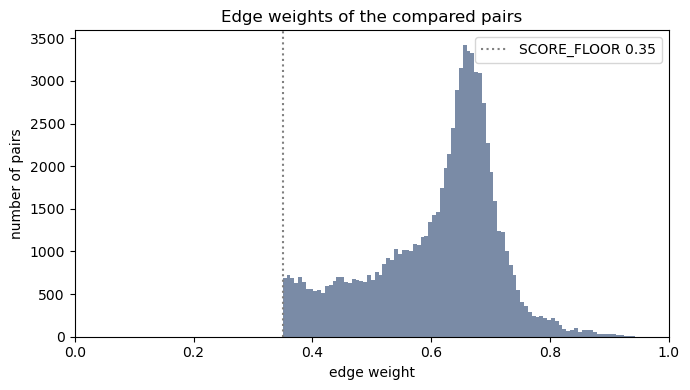

In [6]:
# Histogram of the edge weights (all pairs with weight >= SCORE_FLOOR); weights are always inside [0, 1]
fig, ax = plt.subplots(figsize=(7, 4))                                    # one panel
ax.hist(scored["score"], bins=100, color="#7a8ba6")                       # distribution of the kept weights
ax.axvline(SCORE_FLOOR, color="gray", ls=":", label=f"SCORE_FLOOR {SCORE_FLOOR}")   # lower end of the kept weights
ax.set(title="Edge weights of the compared pairs", xlabel="edge weight", ylabel="number of pairs", xlim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

## Step 3 - Filtering: threshold and graph cut

**Threshold (Otsu).** Some threshold is unavoidable, but we choose it neither by hand nor on the gold standard. It is computed from the weights themselves with Otsu's method (1979): it picks the cut that splits the histogram of weights into two classes (low weights = accidental similarity, high weights = genuine matches) with the largest between-class variance. It uses no labels and is recomputed on every new dataset, so the pipeline can be run on a new sector without a gold standard. (Terrorizer sets its matching threshold empirically and then optimises it on labelled data with TPE, maximising F1; we use no labels.) Otsu's pool is restricted to weights >= `SCORE_FLOOR` so that the huge mass of unrelated pairs does not dominate it.

**Graph and communities.** Names are nodes; every pair with weight >= threshold is an edge carrying its weight. The Louvain algorithm (Blondel et al., 2008) splits the graph into communities by maximising modularity, which uses the edge weights and needs no number of groups. Its resolution is left at the default 1 (also Terrorizer's starting value) and a fixed seed makes the result reproducible. Terrorizer also forms communities with Louvain on a weighted name graph.

**Representative name.** Each community is named after its most frequent name (ties: the shortest). With `WEIGHT_COL` set, frequency is measured in patent families instead of rows.

In [7]:
def find_threshold_otsu(scores, bins=100, floor=SCORE_FLOOR):
    """Otsu's method: the threshold that splits the weights into two classes with the largest between-class variance
    (equivalently, the smallest within-class variance). Uses no labels."""
    s = scores[scores >= floor]                                       # pool: only the plausible weights (>= floor)
    hist, bin_edges = np.histogram(s, bins=bins)                      # histogram of the weights
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0              # centre of every bin

    weight1 = np.cumsum(hist)                                         # number of pairs at or below each bin (class 1)
    weight2 = np.cumsum(hist[::-1])[::-1]                             # number of pairs at or above each bin (class 2)

    mean1 = np.cumsum(hist * bin_centers) / np.maximum(weight1, 1)    # mean weight of class 1 for every candidate cut
    mean2 = (np.cumsum((hist * bin_centers)[::-1]) / np.maximum(weight2[::-1], 1))[::-1]   # mean weight of class 2

    # between-class variance for every candidate cut (class 1 = bins up to i, class 2 = bins from i + 1)
    variance_between = weight1[:-1] * weight2[1:] * (mean1[:-1] - mean2[1:]) ** 2
    idx = np.argmax(variance_between)                                 # the best cut maximises it
    return float(bin_centers[idx])


# Unsupervised threshold (no gold labels used)
th_otsu = find_threshold_otsu(scored["score"].values)
print(f"Otsu threshold (unsupervised): {th_otsu:.3f}")

Otsu threshold (unsupervised): 0.566


In [8]:
# 1. Threshold = Otsu output of THIS run (never a hard-coded value)
TH = th_otsu

# 2. Build the graph and find the communities (Louvain does not need the number of groups)
def cluster(th, seed=LOUVAIN_SEED):
    G = nx.Graph()                                                    # empty undirected graph
    G.add_nodes_from(names)                                           # one node per cleaned name (isolated names stay alone)
    edges = scored[scored["score"] >= th]                             # pairs strong enough to become edges
    G.add_weighted_edges_from(zip(edges["name_a"], edges["name_b"], edges["score"]))   # edge weight = pair score
    return nx_comm.louvain_communities(G, weight="weight", resolution=LOUVAIN_RESOLUTION, seed=seed)

def to_labels(comms):
    return {n: i for i, c in enumerate(comms) for n in c}             # name -> community number

communities = cluster(TH)

# 3. Representative name of each community (most frequent, then shortest)
counts = df.groupby("clean")[WEIGHT_COL].sum() if WEIGHT_COL else df["clean"].value_counts()   # frequency of every name
harmonized_map = {}                                                   # name -> representative name
for members in communities:
    best_name = min(members, key=lambda n: (-counts.get(n, 0), len(n)))   # highest frequency first, then shortest
    for m in members:
        harmonized_map[m] = best_name
df["harmonized"] = df["clean"].map(harmonized_map)                    # harmonised name of every row
print(f"communities: {len(communities):,} | largest community: {max(len(c) for c in communities):,} names")

# 4. Pairwise precision, recall and F1 (course metric); only if the file has a gold column
def pairs_inside(group_sizes):
    return sum(comb(int(n), 2) for n in group_sizes)                  # number of pairs inside groups of the given sizes

def precision_recall_f1(gold_groups, predicted_groups):
    res_df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(res_df.groupby(["gold", "pred"]).size())        # pairs together in both gold and prediction
    tp_fp = pairs_inside(res_df.groupby("pred").size())               # pairs together in the prediction
    tp_fn = pairs_inside(res_df.groupby("gold").size())               # pairs together in the gold standard
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn if tp_fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"groups found": res_df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}

if GROUP_COL in df.columns:
    print(f"True groups in the gold standard: {df[GROUP_COL].nunique()}")
    print(pd.Series(precision_recall_f1(df[GROUP_COL], df["harmonized"])).round(3))
    dn = df.drop_duplicates("clean")        # distinct cleaned names only (identical names are trivially together)
    print("distinct names only:", {k: round(v, 3) for k, v in precision_recall_f1(dn[GROUP_COL], dn["harmonized"]).items()})

communities: 559 | largest community: 170 names
True groups in the gold standard: 481
groups found    559.000
precision         0.920
recall            0.861
F1                0.890
dtype: float64
distinct names only: {'groups found': 559, 'precision': 0.915, 'recall': 0.856, 'F1': 0.885}


### Threshold stability

Otsu does not use the gold standard, so we check what that costs. The next cell sweeps the threshold over a grid and reports precision, recall and F1 for each value, compares Otsu's result with the best value on the grid, and repeats Louvain with ten different seeds.

How to read it: the "best on grid" threshold is chosen *on the gold standard itself*, so it is an optimistic upper bound and is never used as the threshold. The gap F1(best) - F1(Otsu) is the price of choosing the threshold without labels. A small gap and a flat F1 curve around Otsu's value mean that the result is not sensitive to the exact threshold; a standard deviation close to 0 across seeds means that the Louvain randomness does not matter.

In [9]:
# Threshold sensitivity (gold standard only)
if GROUP_COL in df.columns:
    f1_at = lambda th, seed=LOUVAIN_SEED: precision_recall_f1(df[GROUP_COL], df["clean"].map(to_labels(cluster(th, seed))))   # metrics at a threshold
    sweep = pd.DataFrame([{"th": round(float(t), 3), **f1_at(t)} for t in SWEEP_GRID])     # one row per threshold of the grid
    print(sweep.round(3).to_string(index=False))
    best, at_otsu = sweep.loc[sweep["F1"].idxmax()], f1_at(th_otsu)                        # best grid threshold vs Otsu
    print(f"Otsu {th_otsu:.3f}: F1 {at_otsu['F1']:.3f} | best on grid {best['th']:.3f}: F1 {best['F1']:.3f} | loss {best['F1'] - at_otsu['F1']:.3f}")
    seeds = [f1_at(th_otsu, s)["F1"] for s in range(10)]                                   # same threshold, ten Louvain seeds
    print(f"Louvain seeds 0-9 at Otsu: F1 mean {np.mean(seeds):.3f}, sd {np.std(seeds):.3f}")

   th  groups found  precision  recall    F1
0.400           322      0.855   0.958 0.904
0.425           359      0.873   0.949 0.910
0.450           392      0.884   0.942 0.912
0.475           426      0.893   0.938 0.915
0.500           459      0.901   0.925 0.913
0.525           500      0.908   0.898 0.903
0.550           531      0.907   0.881 0.894
0.575           573      0.921   0.860 0.889
0.600           615      0.928   0.837 0.880
0.625           662      0.940   0.816 0.874
0.650           729      0.944   0.761 0.843
0.675           827      0.948   0.697 0.804
0.700           975      0.945   0.602 0.736
0.725          1189      0.954   0.415 0.579
0.750          1415      0.964   0.283 0.438
0.775          1738      0.975   0.148 0.257
0.800          2094      0.974   0.063 0.118
0.825          2344      0.981   0.028 0.054
0.850          2524      0.985   0.015 0.030
Otsu 0.566: F1 0.890 | best on grid 0.475: F1 0.915 | loss 0.025
Louvain seeds 0-9 at Otsu: F1 mean 

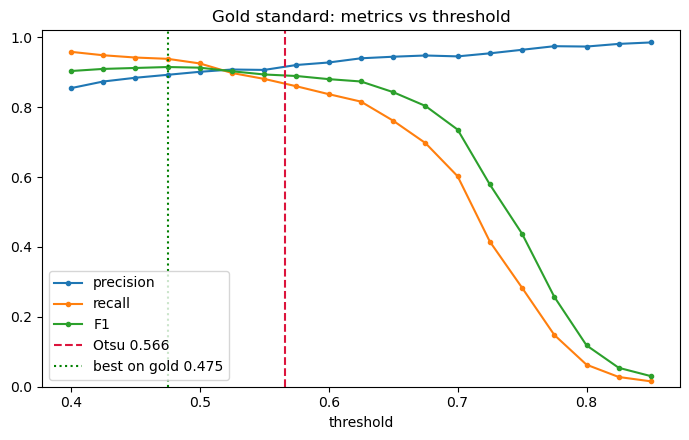

In [10]:
# Chart: precision / recall / F1 versus threshold (gold standard only), with Otsu's threshold and the best one on the grid
if GROUP_COL in df.columns:
    fig, ax = plt.subplots(figsize=(7, 4.5))                                               # one panel
    for col in ("precision", "recall", "F1"):
        ax.plot(sweep["th"], sweep[col], marker="o", ms=3, label=col)                      # one curve per metric
    ax.axvline(th_otsu, color="crimson", ls="--", label=f"Otsu {th_otsu:.3f}")             # unsupervised threshold actually used
    ax.axvline(best["th"], color="green", ls=":", label=f"best on gold {best['th']:.3f}")  # optimistic upper bound
    ax.set(title="Gold standard: metrics vs threshold", xlabel="threshold", ylim=(0, 1.02))
    ax.legend()
    plt.tight_layout()
    plt.show()

## Design choices, differences from Terrorizer and limitations

**What is fixed, and why**
- The threshold that matters most is derived from the data (Otsu), and the Louvain resolution is left at its default (1). The remaining constants - the three weights, `SCORE_FLOOR`, the number of histogram bins in Otsu's method and the cleaning dictionaries - are fixed in the notebook and are **not optimised on the gold standard**.
- The pipeline is deterministic: sorted names, a fixed Louvain seed and no other randomness. Pinning the library versions and the embedding-model revision reproduces it exactly.

**Differences from Terrorizer** (Ascione & Sterzi, 2024)
- Terrorizer tunes nine hyperparameters with TPE on labelled data (objective: F1); here nothing is tuned on labels.
- After Louvain, Terrorizer removes edges between communities with a bridgeness-centrality rule and runs Louvain again inside each community; here Louvain runs once.
- Terrorizer names a community after the name with the highest average cosine similarity to the others; here the most frequent name is used, then the shortest.
- Terrorizer uses extra information to boost edge weights (for example shared locations); here only the names are used.

These simplifications favour transparency and the absence of tuning over maximum accuracy.

**Limitations**
- The gold standard was available while the notebook was developed, so its scores are a *development benchmark*, not a blind test. A sample of the target sector, labelled after the pipeline is frozen, is the appropriate test.
- The gold standard was not built for any specific sector; results on other sectors (acronyms, non-Latin scripts, start-ups) can differ and must be checked on a sample of that sector.
- Pairwise precision and recall are dominated by the largest groups. The largest communities should be inspected by hand: Louvain at a single resolution can merge distinct organisations that share a word (chain merges).
- There is no sensitivity analysis on the three weights, on `SCORE_FLOOR` or on the number of histogram bins: a natural extension.
- The embedding model is third-party and its training data are not documented in the sources we consulted, so an overlap with the evaluation names cannot be excluded.

## References

- Ascione, G. S., & Sterzi, V. (2024). *Presenting Terrorizer: an algorithm for consolidating company names in patent assignees.* arXiv:2403.12083. https://arxiv.org/abs/2403.12083
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.
- Callaert, J., du Plessis, M., Grouwels, J., Lecocq, C., Magerman, T., Peeters, B., Song, X., Van Looy, B., & Vereyen, C. (2011). *Patent statistics at Eurostat: Methods for regionalisation, sector allocation and name harmonisation.* Eurostat Methodologies & Working Papers.
- Magerman, T., Van Looy, B., & Song, X. (2006). *Data production methods for harmonised patent statistics: Patentee name harmonisation.* Eurostat Working Papers and Studies.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62-66.
- Ratcliff, J. W., & Metzener, D. E. (1988). Pattern matching: the Gestalt approach. *Dr. Dobb's Journal*, July 1988 (basis of `difflib.SequenceMatcher`).
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of EMNLP-IJCNLP 2019*.
- Unicode Consortium. *Unicode Standard Annex #15: Unicode Normalization Forms.* https://unicode.org/reports/tr15/
- Vsevolod. *company-names-similarity-sentence-transformer* (model card, Hugging Face). https://huggingface.co/Vsevolod/company-names-similarity-sentence-transformer